# **Extracting Information from Legal Documents Using RAG**

## **Objective**

The main objective of this assignment is to process and analyse a collection text files containing legal agreements (e.g., NDAs) to prepare them for implementing a **Retrieval-Augmented Generation (RAG)** system. This involves:

* Understand the Cleaned Data : Gain a comprehensive understanding of the structure, content, and context of the cleaned dataset.
* Perform Exploratory Analysis : Conduct bivariate and multivariate analyses to uncover relationships and trends within the cleaned data.
* Create Visualisations : Develop meaningful visualisations to support the analysis and make findings interpretable.
* Derive Insights and Conclusions : Extract valuable insights from the cleaned data and provide clear, actionable conclusions.
* Document the Process : Provide a detailed description of the data, its attributes, and the steps taken during the analysis for reproducibility and clarity.

The ultimate goal is to transform the raw text data into a clean, structured, and analysable format that can be effectively used to build and train a RAG system for tasks like information retrieval, question-answering, and knowledge extraction related to legal agreements.

### **Business Value**  


The project aims to leverage RAG to enhance legal document processing for businesses, law firms, and regulatory bodies. The key business objectives include:

* Faster Legal Research: <br> Reduce the time lawyers and compliance officers spend searching for relevant case laws, precedents, statutes, or contract clauses.
* Improved Contract Analysis: <br> Automatically extract key terms, obligations, and risks from lengthy contracts.
* Regulatory Compliance Monitoring: <br> Help businesses stay updated with legal and regulatory changes by retrieving relevant legal updates.
* Enhanced Decision-Making: <br> Provide accurate and context-aware legal insights to assist in risk assessment and legal strategy.


**Use Cases**
* Legal Chatbots
* Contract Review Automation
* Tracking Regulatory Changes and Compliance Monitoring
* Case Law Analysis of past judgments
* Due Diligence & Risk Assessment

## **1. Data Loading, Preparation and Analysis** <font color=red> [20 marks] </font><br>

### **1.1 Data Understanding**

The dataset contains legal documents and contracts collected from various sources. The documents are present as text files (`.txt`) in the *corpus* folder.

There are four types of documents in the *courpus* folder, divided into four subfolders.
- `contractnli`: contains various non-disclosure and confidentiality agreements
- `cuad`: contains contracts with annotated legal clauses
- `maud`: contains various merger/acquisition contracts and agreements
- `privacy_qa`: a question-answering dataset containing privacy policies

The dataset also contains evaluation files in JSON format in the *benchmark* folder. The files contain the questions and their answers, along with sources. For the above folders, there is a `json` file: `contractnli.json`, `cuad.json`, `maud.json`. The file structure is as follows:

```
{
    "tests": [
        {
            "query": <question1>,
            "snippets": [{
                    "file_path": <source_file1>,
                    "span": [ begin_position, end_position ],
                    "answer": <relevant answer to the question 1>
                },
                {
                    "file_path": <source_file2>,
                    "span": [ begin_position, end_position ],
                    "answer": <relevant answer to the question 2>
                }, ....
            ]
        },
        {
            "query": <question2>,
            "snippets": [{<answer context for que 2>}]
        },
        ... <more queries>
    ]
}
```

### **1.2 Load and Preprocess the data** <font color=red> [5 marks] </font><br>

#### Loading libraries

In [2]:
## The following libraries might be useful
# !pip install -q langchain-openai
# !pip install -U -q langchain-community
# !pip install -U -q langchain-chroma
# !pip install -U -q datasets
# !pip install -U -q ragas
# !pip install -U -q rouge_score
# Versions pinned so the LCEL, langchain-chroma and ragas 0.2.x APIs used below stay compatible
!pip install -q "langchain==0.3.27" "langchain-community==0.3.29" "langchain-text-splitters==0.3.11" "langchain-openai==0.3.33" "langchain-chroma==0.2.6" "ragas==0.2.15" datasets rouge_score scikit-learn pandas matplotlib seaborn tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
langgraph-prebuilt 1.1.1 requires langchain-core>=1.3.1, but you have langchain-core 0.3.86 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires p

In [3]:
# Import essential libraries
import os, re, json, random, hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity

from langchain_community.document_loaders import DirectoryLoader, TextLoader
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnableParallel, RunnablePassthrough
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_chroma import Chroma

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
# Google Colab: the dataset is in My Drive/rag_legal. The vector DB is kept on the local disk (/content)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/rag_legal")
    CHROMA_DIR = Path("/content/chroma_legal_db")
except ImportError:
    DATA_DIR = Path("rag_legal")
    CHROMA_DIR = Path("chroma_legal_db")

CORPUS_DIR, BENCH_DIR = DATA_DIR / "corpus", DATA_DIR / "benchmarks"
print("Corpus:", sorted(p.name for p in CORPUS_DIR.iterdir() if p.is_dir() and not p.name.startswith(".")))
print("Benchmarks:", sorted(p.name for p in BENCH_DIR.glob("*.json")))


#### **1.2.1** <font color=red> [3 marks] </font>
Load all `.txt` files from the folders.

You can utilise document loaders from the options provided by the LangChain community.

Optionally, you can also read the files manually, while ensuring proper handling of encoding issues (e.g., utf-8, latin1). In such case, also store the file content along with metadata (e.g., file name, directory path) for traceability.

In [4]:
# Load the files as documents

loader = DirectoryLoader(
    str(CORPUS_DIR), glob="**/*.txt", loader_cls=TextLoader,
    loader_kwargs={"encoding": "utf-8", "autodetect_encoding": True}, silent_errors=True,
)
raw_docs = loader.load()

documents, alias_of, seen_hash = [], {}, {}
for d in sorted(raw_docs, key=lambda x: x.metadata["source"]):
    if not d.page_content.strip():
        continue
    rel = Path(d.metadata["source"]).relative_to(CORPUS_DIR).as_posix()
    digest = hashlib.md5(d.page_content.encode("utf-8")).hexdigest()
    if digest in seen_hash:
        alias_of[rel] = seen_hash[digest]
        continue
    seen_hash[digest] = rel
    d.metadata.update({
        "rel_path": rel,
        "category": rel.split("/")[0],
        "title": re.sub(r"[_\-]+|%20", " ", Path(rel).stem).strip(),
    })
    documents.append(d)

doc_text = {d.metadata["rel_path"]: d.page_content for d in documents}
print(f"Files loaded: {len(raw_docs)} | documents kept: {len(documents)} | duplicates mapped: {len(alias_of)}")
display(pd.Series([d.metadata["category"] for d in documents]).value_counts().rename("documents").to_frame())




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Corpus: ['contractnli', 'cuad', 'maud', 'privacy_qa']
Benchmarks: ['contractnli.json', 'cuad.json', 'maud.json']
Files loaded: 644 | documents kept: 642 | duplicates mapped: 2


,documents
cuad,430
maud,117
contractnli,92
privacy_qa,3


#### **1.2.2** <font color=red> [2 marks] </font>
Preprocess the text data to remove noise and prepare it for analysis.

Remove special characters, extra whitespace, and irrelevant content such as email and telephone contact info.
Normalise text (e.g., convert to lowercase, remove stop words).
Handle missing or corrupted data by logging errors and skipping problematic files.

In [5]:
# Clean and preprocess the data
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Legal words change the meaning of a clause ("shall not", "any and all", "no obligation"), so they are kept
LEGAL_WORDS = {
    "no", "not", "nor", "none", "never", "any", "all", "each", "every", "both", "either", "neither",
    "only", "except", "without", "against", "before", "after", "under", "over", "between", "other",
    "such", "own", "more", "most", "same", "may", "must", "upon", "whereas", "whereby", "wherein",
    "herein", "hereby", "therein", "thereby", "thereupon", "also",
}
STOP_WORDS = ENGLISH_STOP_WORDS - LEGAL_WORDS

NOISE_PATTERNS = [
    r"[\w.+-]+@[\w-]+\.[\w.-]+",   # e-mail addresses
    r"https?://\S+|www\.\S+",      # URLs
    r"\[\s*(\*\s*)+\]|\*{3,}",     # redaction markers such as "[ * * * ]"
]


def clean_text(text):
    text = text.lower()
    for pattern in NOISE_PATTERNS:
        text = re.sub(pattern, " ", text)
    words = re.sub(r"[^a-z\s]", " ", text).split()           # drops digits, punctuation and phone numbers
    return " ".join(w for w in words if len(w) > 1 and w not in STOP_WORDS)


for d in documents:
    d.metadata["clean_text"] = clean_text(d.page_content)

df_docs = pd.DataFrame([{
    "rel_path": d.metadata["rel_path"],
    "category": d.metadata["category"],
    "n_chars": len(d.page_content),
    "n_words": len(d.page_content.split()),
    "clean_text": d.metadata["clean_text"],
} for d in documents])
df_docs["n_clean_tokens"] = df_docs["clean_text"].str.split().str.len()

print(f"Average share of tokens removed: {100 * (1 - df_docs['n_clean_tokens'].sum() / df_docs['n_words'].sum()):.1f}%")
print("\nRAW  :", " ".join(documents[0].page_content[:300].split()))
print("CLEAN:", documents[0].metadata["clean_text"][:300])


Average share of tokens removed: 42.6%

RAW  : MUTUAL NON-DISCLOSURE AGREEMENT Between AND Subject Matter: Effective Date of Agreement: Period , 2017 for Exchange of Information: , 2017 to Period of Confidentiality: THIS AGREEMENT is made as of the Effective Date of Agreement noted above, by and between the above parties. BACKGROUND: I. The part
CLEAN: mutual non disclosure agreement between subject matter effective date agreement period exchange information period confidentiality agreement effective date agreement noted between parties background parties desire discussions relating subject matter purposes evaluating possible business relationship


### **1.3 Exploratory Data Analysis** <font color=red> [10 marks] </font><br>

#### **1.3.1** <font color=red> [2 marks] </font>
Calculate the average, maximum and minimum document length.

,mean,median,min,max
words (all),15294.0,5552.0,223.0,156415.0


,count,mean,median,min,max
category,,,,,
contractnli,92,1613.0,1434.0,384,5169
cuad,430,7845.0,5292.0,223,47733
maud,117,53745.0,51864.0,16340,156415
privacy_qa,3,2963.0,4098.0,519,4271


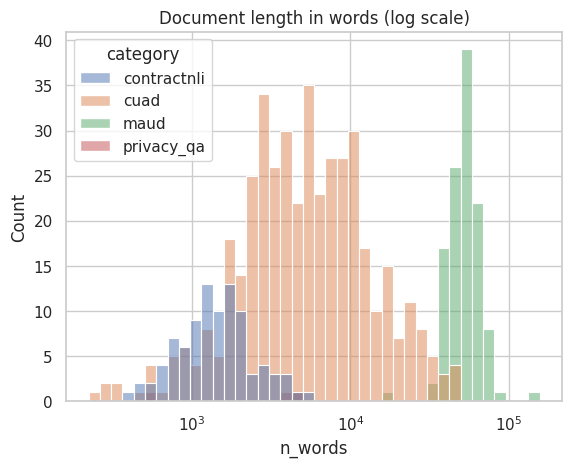

In [6]:
# Calculate the average, maximum and minimum document length.

display(df_docs["n_words"].agg(["mean", "median", "min", "max"]).round(0).to_frame("words (all)").T)
display(df_docs.groupby("category")["n_words"].agg(["count", "mean", "median", "min", "max"]).round(0))

sns.histplot(data=df_docs, x="n_words", hue="category", log_scale=True, bins=40)
plt.title("Document length in words (log scale)")
plt.show()

**Observations**
- Document lengths range from a few hundred words to more than 100k words. The distribution is strongly right-skewed, so the mean is much higher than the median.
- MAUD merger agreements are by far the longest. CUAD contracts are medium-sized, and ContractNLI NDAs and privacy policies are short.
- Whole documents cannot be sent to an LLM, so chunking is required. Long MAUD documents also contain many near-identical clauses, which makes retrieval harder.


#### **1.3.2** <font color=red> [4 marks] </font>
Analyse the frequency of occurence of words and find the most and least occuring words.

Find the 20 most common and least common words in the text. Ignore stop words such as articles and prepositions.

,most_word,most_count,least_word,least_count
0,any,218903,aaaaaaaaaa,1
1,company,135774,aai,1
2,shall,95591,aaldo,1
3,such,94267,aam,1
4,agreement,92878,aarphealthcare,1
5,other,76965,aarpmagazine,1
6,section,65901,aase,1
7,parent,54884,abbey,1
8,not,53149,abbott,1
9,party,48769,abduction,1


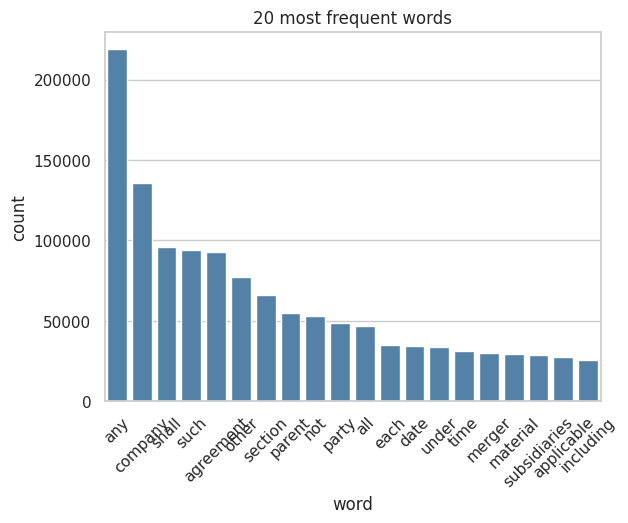

In [7]:
# Find frequency of occurence of words

word_counts = Counter(w for text in df_docs["clean_text"] for w in text.split())
most_common = pd.DataFrame(word_counts.most_common(20), columns=["word", "count"])
least_common = pd.DataFrame(sorted(word_counts.items(), key=lambda x: (x[1], x[0]))[:20], columns=["word", "count"])

display(pd.concat([most_common.add_prefix("most_"), least_common.add_prefix("least_")], axis=1))

sns.barplot(data=most_common, x="word", y="count", color="steelblue")
plt.title("20 most frequent words")
plt.xticks(rotation=45)
plt.show()

#### **1.3.3** <font color=red> [4 marks] </font>
Analyse the similarity of different documents to each other based on TF-IDF vectors.

Transform some documents to TF-IDF vectors and calculate their similarity matrix using a suitable distance function. If contracts contain duplicate or highly similar clauses, similarity calculation can help detect them.

Identify for the first 10 documents and then for 10 random documents. What do you observe?

TF-IDF matrix shape: (642, 30000)


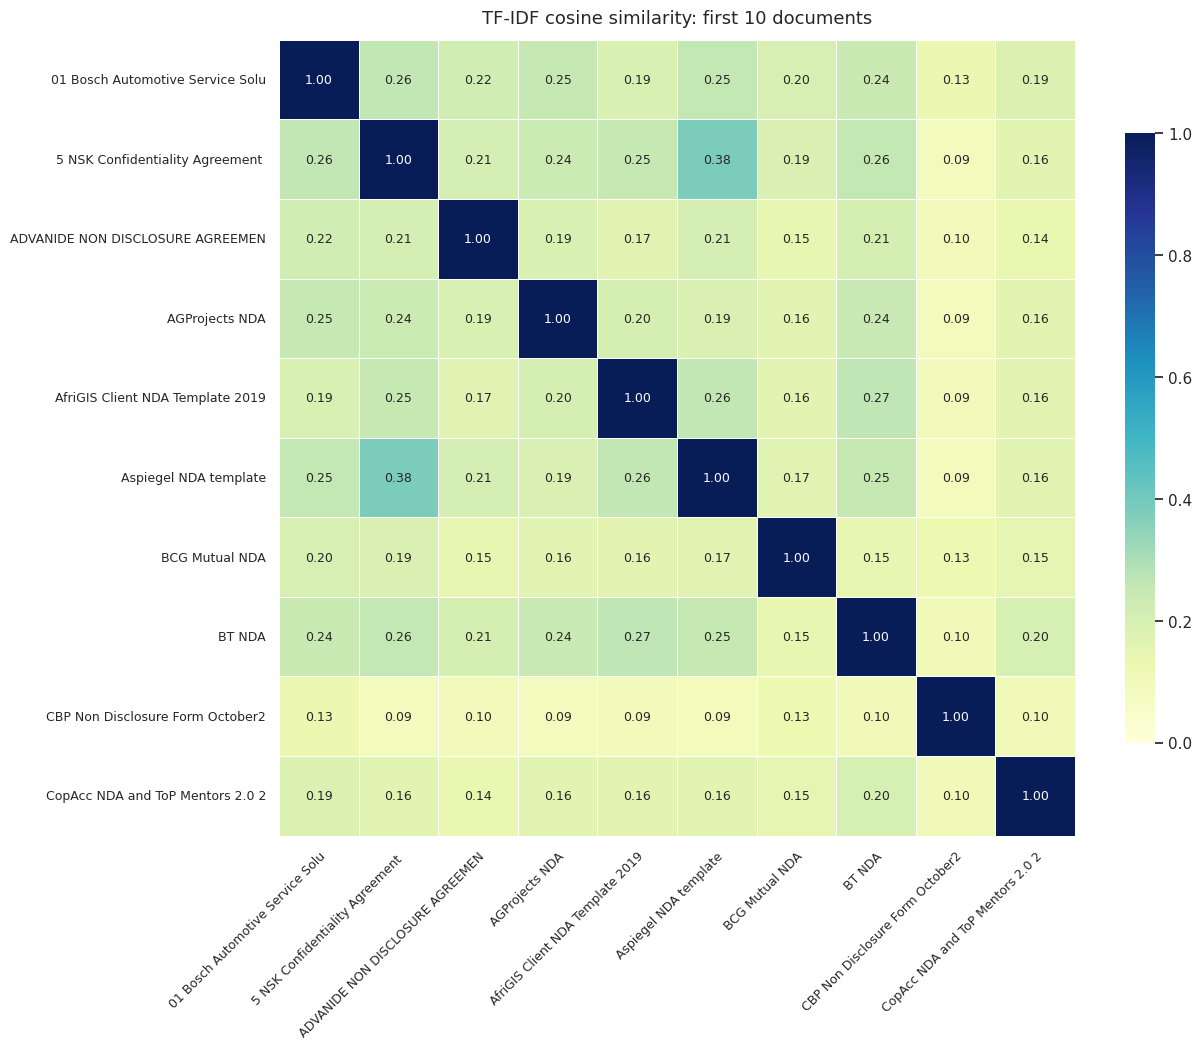

In [13]:
# Transform the page contents of documents
tfidf = TfidfVectorizer(max_features=30000, min_df=2, max_df=0.95, sublinear_tf=True, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(df_docs["clean_text"])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

# Compute similarity scores
def plot_similarity(indices, title):
    sim = cosine_similarity(tfidf_matrix[indices])
    labels = [documents[i].metadata["title"][:32] for i in indices]
    n = len(indices)
    fig, ax = plt.subplots(figsize=(0.9 * n + 4, 0.8 * n + 3))
    sns.heatmap(sim, annot=True, fmt=".2f", annot_kws={"size": 9}, cmap="YlGnBu", linewidths=0.5,
                xticklabels=labels, yticklabels=labels, vmin=0, vmax=1, square=True,
                cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(title, fontsize=13, pad=12)
    ax.tick_params(axis="x", labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()


plot_similarity(list(range(10)), "TF-IDF cosine similarity: first 10 documents")

In [14]:
# create a list of 10 random integers
random.seed(SEED)
random_10 = sorted(random.sample(range(len(df_docs)), 10))
print("Random document indices:", random_10)
display(df_docs.loc[random_10, ["rel_path", "category", "n_words"]])



Random document indices: [25, 89, 104, 114, 142, 228, 250, 281, 558, 604]


,rel_path,category,n_words
25,contractnli/IGC-Non-Disclosure-Agreement-LSE-S...,contractnli,2556
89,contractnli/tpi-non-disclosure-agreement_1.txt,contractnli,1669
104,cuad/ALLISONTRANSMISSIONHOLDINGSINC_12_15_2014...,cuad,5202
114,cuad/AURASYSTEMSINC_06_16_2010-EX-10.25-STRATE...,cuad,6938
142,cuad/BLUEFLYINC_03_27_2002-EX-10.27-e-business...,cuad,5136
228,cuad/FuelcellEnergyInc_20191106_8-K_EX-10.1_11...,cuad,15880
250,cuad/GopageCorp_20140221_10-K_EX-10.1_8432966_...,cuad,6030
281,"cuad/INTELLIGENTHIGHWAYSOLUTIONS,INC_01_18_201...",cuad,1217
558,"maud/FLIR Systems, Inc._Teledyne Technologies ...",maud,54446
604,"maud/People_s United Financial, Inc._M_T Bank ...",maud,60077


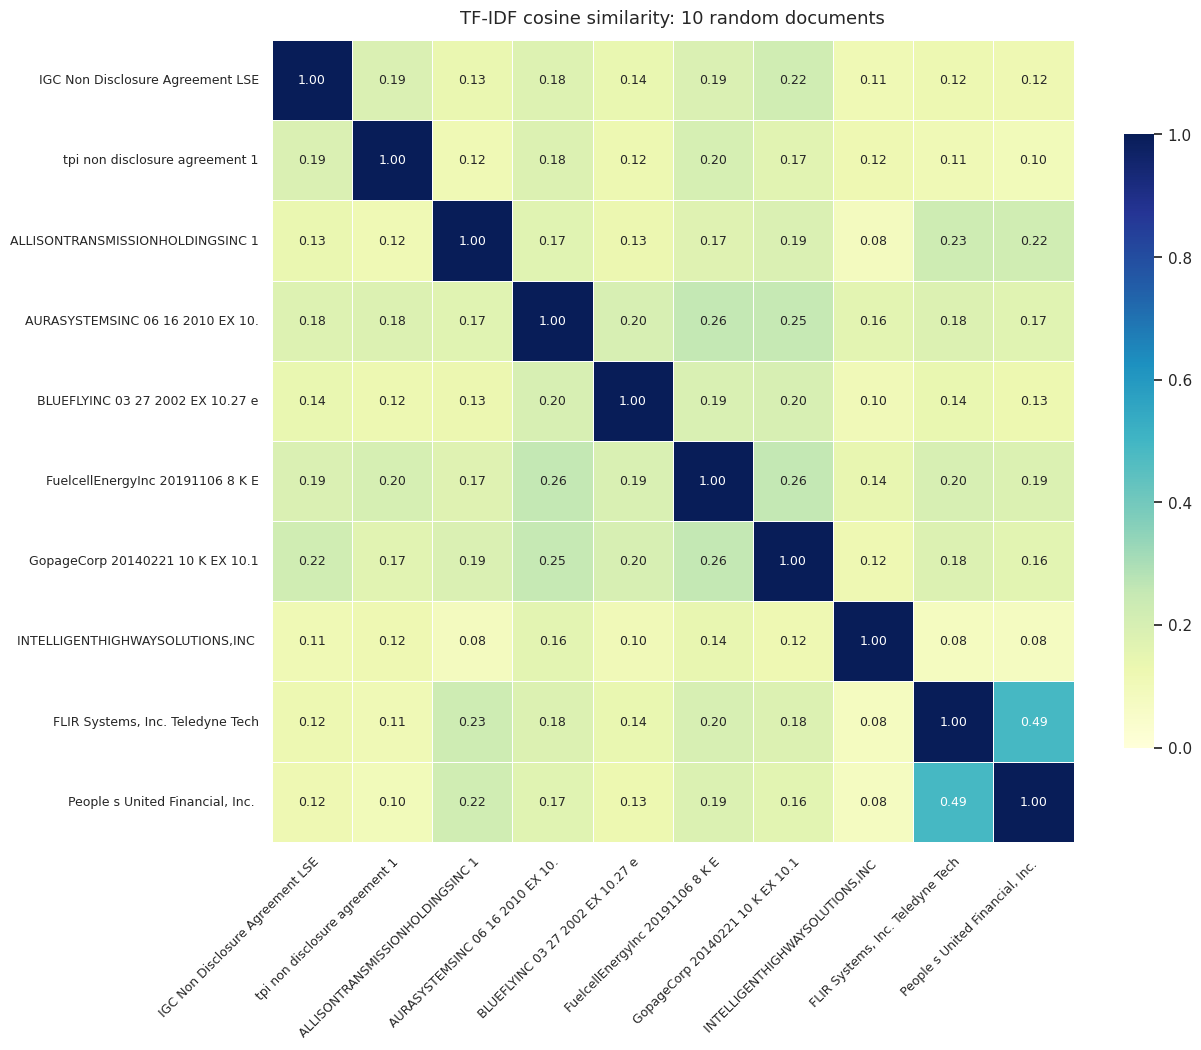

In [15]:
# Compute similarity scores for 10 random documents

plot_similarity(random_10, "TF-IDF cosine similarity: 10 random documents")

### **1.4 Document Creation and Chunking** <font color=red> [5 marks] </font><br>

#### **1.4.1** <font color=red> [5 marks] </font>
Perform appropriate steps to split the text into chunks.

In [16]:
# Process files and generate chunks

CHUNK_SIZE, CHUNK_OVERLAP = 1000, 200
CATEGORY_DESC = {
    "contractnli": "Non-Disclosure / Confidentiality Agreement",
    "cuad": "Commercial Contract",
    "maud": "Merger / Acquisition Agreement",
    "privacy_qa": "Privacy Policy",
}

splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", "; ", ", ", " ", ""],
    add_start_index=True,                      # character offset, needed for span-level evaluation
)

chunks = []
for d in documents:
    base = Document(page_content=d.page_content,
                    metadata={k: v for k, v in d.metadata.items() if k != "clean_text"})
    for ch in splitter.split_documents([base]):
        if len(ch.page_content.strip()) < 50:             # skip page numbers and blank fragments
            continue
        meta = ch.metadata
        meta["end_index"] = meta["start_index"] + len(ch.page_content)
        meta["raw_text"] = ch.page_content
        # The title header ties each clause to its contract when it is embedded
        ch.page_content = f"Document: {meta['title']} ({CATEGORY_DESC[meta['category']]})\n{meta['raw_text']}"
        chunks.append(ch)

print(f"{len(documents)} documents -> {len(chunks):,} chunks")
display(pd.Series([c.metadata["category"] for c in chunks]).value_counts().rename("chunks").to_frame())

bad = sum(doc_text[c.metadata["rel_path"]][c.metadata["start_index"]:c.metadata["end_index"]] != c.metadata["raw_text"]
          for c in chunks)
print("Chunks whose offsets do not match the source text:", bad)

642 documents -> 95,368 chunks


,chunks
maud,61118
cuad,32764
contractnli,1411
privacy_qa,75


Chunks whose offsets do not match the source text: 0


## **2. Vector Database and RAG Chain Creation** <font color=red> [15 marks] </font><br>

### **2.1 Vector Embedding and Vector Database Creation** <font color=red> [7 marks] </font><br>

#### **2.1.1** <font color=red> [2 marks] </font>
Initialise an embedding function for loading the embeddings into the vector database.

Initialise a function to transform the text to vectors using an embedding model. You can also use this function to transform during vector DB creation itself.

In [24]:
# Fetch your API Key as an environment variable (or load it directly if variable naming is conventional)

try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPEN_API_KEY")     # saved in the Colab Secrets (key icon)
    print("Running on Colab: reading the key from Colab Secrets (OPEN_API_KEY)")
except ImportError:
    print("Running locally: reading the key from the OPENAI_API_KEY environment variable")

assert os.environ.get("OPENAI_API_KEY"), "OpenAI key not found. Add OPEN_API_KEY in Colab Secrets."
key = os.environ["OPENAI_API_KEY"]
print(f"OpenAI key found: yes (ends with ...{key[-4:]}, length {len(key)})")

Running on Colab: reading the key from Colab Secrets (OPEN_API_KEY)
OpenAI key found: yes (ends with ...xAwA, length 164)


In [25]:
# Initialise an embedding function

EMBEDDING_MODEL = "text-embedding-3-small"
embedding_function = OpenAIEmbeddings(model=EMBEDDING_MODEL, chunk_size=256, max_retries=6)
print("Embedding dimensions:", len(embedding_function.embed_query("What is the governing law?")))

Embedding dimensions: 1536


#### **2.1.2** <font color=red> [5 marks] </font>
Load the embeddings to a vector database.

Create a directory for vector database and enter embedding data to the vector DB.

In [26]:
# Add Chunks to vector DB

vector_db = Chroma(
    collection_name="legal_docs",
    embedding_function=embedding_function,
    persist_directory=str(CHROMA_DIR),
    collection_metadata={"hnsw:space": "cosine"},
)

chunk_ids = [hashlib.md5(f"{c.metadata['rel_path']}::{c.metadata['start_index']}".encode()).hexdigest() for c in chunks]

# Chunks already stored are skipped.
stored = set(vector_db.get(include=[])["ids"])
todo = [(i, c) for i, c in zip(chunk_ids, chunks) if i not in stored]
for b in tqdm(range(0, len(todo), 2000), desc="Embedding"):
    batch = todo[b:b + 2000]
    vector_db.add_documents([c for _, c in batch], ids=[i for i, _ in batch])

print("Vectors in database:", vector_db._collection.count())

Embedding:   0%|          | 0/48 [00:00<?, ?it/s]

Vectors in database: 95368


### **2.2 Create RAG Chain** <font color=red> [8 marks] </font><br>

#### **2.2.1** <font color=red> [5 marks] </font>
Form the complete RAG pipeline.

You can either create a chain or directly the pipeline

In [29]:
# Create a RAG chain
TOP_K, LLM_MODEL = 5, "gpt-4o-mini"
llm = ChatOpenAI(model=LLM_MODEL, temperature=0, max_tokens=600)

RAG_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are a meticulous legal assistant. Answer the question using ONLY the numbered context excerpts. Rules:\n"
     "1. Do not use outside knowledge or speculate.\n"
     "2. Prefer excerpts from the contract named in the question.\n"
     "3. Quote the exact clause that answers the question, then explain it briefly in plain English. "
     "For yes/no questions, start with 'Yes' or 'No'.\n"
     "4. Cite the excerpt numbers you used, e.g. [1], [3].\n"
     "5. If the context does not contain the answer, say: 'The provided documents do not contain this information.'"),
    ("human", "Context excerpts:\n{context}\n\nQuestion: {question}\n\nAnswer:"),
])


def format_docs(docs):
    return "\n\n".join(
        f"[{i}] Source: {d.metadata['rel_path']} (chars {d.metadata['start_index']}-{d.metadata['end_index']})\n"
        f"{d.metadata['raw_text']}"
        for i, d in enumerate(docs, start=1)
    )


answer_chain = (
    RunnableLambda(lambda x: {"context": format_docs(x["context"]), "question": x["question"]})
    | RAG_PROMPT
    | llm
    | StrOutputParser()
)

#### **2.2.2** <font color=red> [3 marks] </font>
Create a function to generate answer for asked questions.

Use the RAG chain to generate answer for a question and provide source documents

In [30]:
# Create a function for question answering

def answer_question(question, k=TOP_K, category=None, verbose=True):
    search = {"k": k} if category is None else {"k": k, "filter": {"category": category}}
    chain = RunnableParallel(
        context=vector_db.as_retriever(search_kwargs=search),
        question=RunnablePassthrough(),
    ).assign(answer=answer_chain)

    out = chain.invoke(question)
    docs = out["context"]
    result = {
        "question": question,
        "answer": out["answer"],
        "docs": docs,
        "sources": [f"{d.metadata['rel_path']} (chars {d.metadata['start_index']}-{d.metadata['end_index']})" for d in docs],
    }
    if verbose:
        print("ANSWER:\n" + result["answer"] + "\n")
        print("SOURCES:\n" + "\n".join(result["sources"]))
    return result

In [31]:
# Example question
# question ="Consider the Non-Disclosure Agreement between CopAcc and ToP Mentors; Does the document indicate that the Agreement does not grant the Receiving Party any rights to the Confidential Information?"
question = "Consider the Non-Disclosure Agreement between CopAcc and ToP Mentors; Does the document indicate that the Agreement does not grant the Receiving Party any rights to the Confidential Information?"
res = answer_question(question)

for q in [
    "Consider the Marketing Affiliate Agreement between Birch First Global Investments Inc. and Mount Knowledge Holdings Inc.; What is the expiration date of this contract?",
    "Does Fiverr sell or rent users' personal information to third parties?",
]:
    answer_question(q)
    print("-" * 100)

ANSWER:
Yes. 

The document states, "Any and all proprietary rights, including but not limited to rights to and in inventions, patent rights, utility models, copyrights, trademarks and trade secrets, in and to any Confidential Information shall be and remain with the Participants respectively, and Mentor shall not have any right, license, title or interest in or to any Confidential Information, except the limited right to review, assess and help develop such Confidential Information in connection with the Copernicus Accelerator 2017" [4]. 

This means that the Mentor (Receiving Party) does not gain any ownership or rights to the Confidential Information, except for the specific purpose of reviewing and developing it as part of the program. The rights remain with the Participants. 

Cited excerpt: [4].

SOURCES:
contractnli/CopAcc_NDA-and-ToP-Mentors_2.0_2017.txt (chars 8534-9377)
contractnli/CopAcc_NDA-and-ToP-Mentors_2.0_2017.txt (chars 7711-8666)
contractnli/CopAcc_NDA-and-ToP-Mentor

## **3. RAG Evaluation** <font color=red> [10 marks] </font><br>

### **3.1 Evaluation and Inference** <font color=red> [10 marks] </font><br>

#### **3.1.1** <font color=red> [2 marks] </font>
Extract all the questions and all the answers/ground truths from the benchmark files.

Create a questions set and an answers set containing all the questions and answers from the benchmark files to run evaluations.

In [32]:
# Create a question set by taking all the questions from the benchmark data
# Also create a ground truth/answer set
rows = []
for f in sorted(BENCH_DIR.glob("*.json")):
    for t in json.loads(f.read_text(encoding="utf-8"))["tests"]:
        files = [alias_of.get(s["file_path"], s["file_path"]) for s in t["snippets"]]
        rows.append({
            "benchmark": f.stem,
            "query": t["query"].strip(),
            "ground_truth": "\n".join(s["answer"].strip() for s in t["snippets"]),
            "gold_spans": [(fp, s["span"][0], s["span"][1]) for fp, s in zip(files, t["snippets"])],
            "in_corpus": all(fp in doc_text for fp in files),
        })

bench_df = pd.DataFrame(rows)
eval_pool = bench_df[bench_df["in_corpus"]].reset_index(drop=True)
questions = bench_df["query"].tolist()
ground_truths = bench_df["ground_truth"].tolist()

display(bench_df.groupby("benchmark").agg(questions=("query", "count"), answerable=("in_corpus", "sum")))
print(f"Total questions: {len(questions):,} | usable for evaluation: {len(eval_pool):,}")
print("No benchmark file exists for 'privacy_qa', so its documents are indexed but cannot be scored.")


,questions,answerable
benchmark,,
contractnli,977,962
cuad,4042,3739
maud,1676,1308


Total questions: 6,695 | usable for evaluation: 6,009
No benchmark file exists for 'privacy_qa', so its documents are indexed but cannot be scored.


#### **3.1.2** <font color=red> [5 marks] </font>
Create a function to evaluate the generated answers and retrieved contexts.

Evaluate the responses with *Ragas*. Additionally check the retrieval quality using 2 retrieval-driven metrics.

In [33]:
# Function to evaluate the RAG pipeline
from rouge_score import rouge_scorer
from ragas import EvaluationDataset, evaluate as ragas_evaluate
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper
from ragas.metrics import (Faithfulness, ResponseRelevancy, LLMContextPrecisionWithReference,
                           LLMContextRecall, FactualCorrectness)

rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)


def overlaps(doc, gold):
    fp, start, end = gold
    return (doc.metadata["rel_path"] == fp and
            max(doc.metadata["start_index"], start) < min(doc.metadata["end_index"], end))


def retrieval_metrics(docs, gold_spans):
    hits = [any(overlaps(d, g) for g in gold_spans) for d in docs]           # retrieved chunk is in the answer span
    covered = [any(overlaps(d, g) for d in docs) for g in gold_spans]         # answer span is covered by a chunk
    first = next((i for i, h in enumerate(hits) if h), None)
    return {
        "doc_hit": float(any(d.metadata["rel_path"] in {g[0] for g in gold_spans} for d in docs)),
        "span_hit": float(any(hits)),
        "rr": 0.0 if first is None else 1 / (first + 1),
        "span_recall": float(np.mean(covered)),
        "precision": float(np.mean(hits)) if hits else 0.0,
    }


def evaluate_retrieval(sample, k):
    rows = []
    for _, r in sample.iterrows():
        rows.append(retrieval_metrics(vector_db.similarity_search(r["query"], k=k), r["gold_spans"]))
    return pd.DataFrame(rows).mean()


def evaluate_rag(sample):
    rows, ragas_rows = [], []
    for _, r in tqdm(sample.iterrows(), total=len(sample), desc="RAG"):
        out = answer_question(r["query"], verbose=False)
        rows.append({
            "benchmark": r["benchmark"], "query": r["query"], "ground_truth": r["ground_truth"],
            "answer": out["answer"], **retrieval_metrics(out["docs"], r["gold_spans"]),
            "rougeL": rouge.score(r["ground_truth"], out["answer"])["rougeL"].fmeasure,
        })
        ragas_rows.append({
            "user_input": r["query"], "retrieved_contexts": [d.metadata["raw_text"] for d in out["docs"]],
            "response": out["answer"], "reference": r["ground_truth"],
        })

    ragas_df = ragas_evaluate(
        dataset=EvaluationDataset.from_list(ragas_rows),
        metrics=[Faithfulness(), ResponseRelevancy(), LLMContextPrecisionWithReference(),
                 LLMContextRecall(), FactualCorrectness(mode="f1")],
        llm=LangchainLLMWrapper(ChatOpenAI(model=LLM_MODEL, temperature=0)),
        embeddings=LangchainEmbeddingsWrapper(embedding_function),
    ).to_pandas()
    metric_cols = [c for c in ragas_df.columns if c not in ("user_input", "retrieved_contexts", "response", "reference")]
    return pd.concat([pd.DataFrame(rows), ragas_df[metric_cols]], axis=1)


#### **3.1.3** <font color=red> [3 marks] </font>
Draw inferences by evaluating answers to questions.

To save time and computing power, you can just run the evaluation on 10 randomly sampled questions.

Retrieval metrics on 300 random questions


,k=1,k=3,k=5,k=10
Doc Hit Rate,0.930,0.943,0.957,0.957
Hit Rate (span),0.267,0.467,0.560,0.700
MRR,0.267,0.351,0.372,0.391
Span Recall,0.221,0.399,0.487,0.622
Precision,0.267,0.184,0.140,0.095


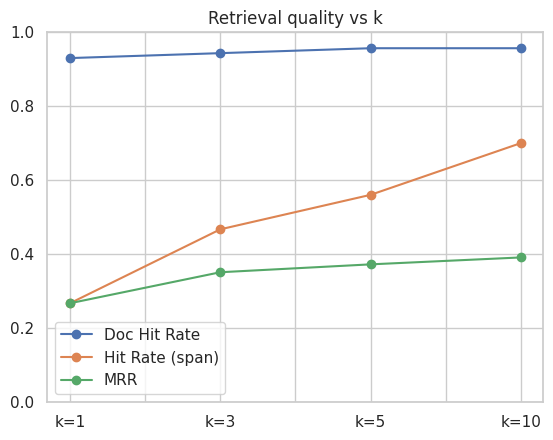

RAG:   0%|          | 0/10 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/50 [00:00<?, ?it/s]

Mean scores on 10 random questions


,score
doc_hit,0.900
span_hit,0.400
rr,0.225
span_recall,0.400
precision,0.120
rougeL,0.218
faithfulness,0.623
answer_relevancy,0.426
llm_context_precision_with_reference,0.554
context_recall,0.750


,benchmark,query,doc_hit,span_hit,rr,span_recall,precision,rougeL,faithfulness,answer_relevancy,llm_context_precision_with_reference,context_recall,factual_correctness(mode=f1)
0,contractnli,Consider Excelerate's Non-Disclosure Agreement...,1.0,1.0,0.25,1.0,0.2,0.64,1.00,0.76,0.25,1.0,0.86
1,cuad,Consider the Sponsorship Agreement between iPa...,0.0,0.0,0.00,0.0,0.0,0.04,0.00,0.27,0.00,0.0,0.00
2,cuad,Consider the Promotion Agreement between Depom...,1.0,0.0,0.00,0.0,0.0,0.18,0.50,0.62,1.00,1.0,0.20
3,cuad,Consider the Exclusive Distributor Agreement b...,1.0,1.0,0.50,1.0,0.2,0.54,0.86,0.63,1.00,1.0,0.67
4,cuad,Consider the Joint Venture Agreement between K...,1.0,1.0,1.00,1.0,0.2,0.05,1.00,0.20,1.00,1.0,0.00
5,maud,"Consider the Merger Agreement between ""GI DI O...",1.0,0.0,0.00,0.0,0.0,0.06,0.00,0.28,0.59,1.0,0.00
6,cuad,Consider the Distributor Agreement between PPG...,1.0,0.0,0.00,0.0,0.0,0.05,0.00,0.17,0.00,1.0,0.00
7,contractnli,Consider AfriGIS's Non-Disclosure Agreement; D...,1.0,1.0,0.50,1.0,0.6,0.39,1.00,0.62,1.00,1.0,0.86
8,cuad,Consider the Yield Maintenance Agreement for I...,1.0,0.0,0.00,0.0,0.0,0.00,1.00,0.18,0.00,0.0,0.00
9,cuad,Consider the Development Agreement between Car...,1.0,0.0,0.00,0.0,0.0,0.24,0.88,0.53,0.70,0.5,0.18


[contractnli] Consider Excelerate's Non-Disclosure Agreement; Does the document state that Confidential Information shall only include technical information?
  GROUND TRUTH: Each Party's Proprietary Information may include, but is not limited to, patents, copyrights, design methods, ideas, concepts, data, formulas, manufacturing techniques, know-how, business plans, customer lists, solicitation response strategies, technical solutions to client requirements, system arch
  RAG ANSWER  : No. The document does not state that Confidential Information shall only include technical information. It defines "PROPRIETARY Information" to include a wide range of information types, not limited to technical information. Specifically, it states that Proprietary Information may include "patents, copyrights, design methods, ideas, concepts, data, formulas, manufacturing techniques, know-how, bus
----------------------------------------------------------------------------------------------------
[cuad] 

In [34]:
# Evaluate the RAG pipeline
# (a) Retrieval metrics on a larger random sample (cheap: embeddings only)
retr_sample = eval_pool.sample(n=min(300, len(eval_pool)), random_state=SEED)
retr_summary = pd.DataFrame({f"k={k}": evaluate_retrieval(retr_sample, k) for k in (1, 3, 5, 10)}).rename(index={
    "doc_hit": "Doc Hit Rate", "span_hit": "Hit Rate (span)", "rr": "MRR",
    "span_recall": "Span Recall", "precision": "Precision"})
print(f"Retrieval metrics on {len(retr_sample)} random questions")
display(retr_summary.round(3))

retr_summary.T[["Doc Hit Rate", "Hit Rate (span)", "MRR"]].plot(marker="o", title="Retrieval quality vs k")
plt.ylim(0, 1)
plt.show()

# (b) RAG evaluation (Ragas + retrieval + ROUGE) on 10 randomly sampled questions
rag_sample = eval_pool.sample(n=10, random_state=SEED)
rag_results = evaluate_rag(rag_sample)
rag_summary = rag_results.select_dtypes("number").mean()
print("Mean scores on 10 random questions")
display(rag_summary.round(3).to_frame("score"))
display(rag_results.drop(columns=["answer", "ground_truth"]).round(2))

for _, r in rag_results.iterrows():
    print(f"[{r['benchmark']}] {r['query']}")
    print(f"  GROUND TRUTH: {r['ground_truth'][:300]}")
    print(f"  RAG ANSWER  : {r['answer'][:400]}")
    print("-" * 100)

## **4. Conclusion** <font color=red> [5 marks] </font><br>

### **4.1 Conclusions and insights** <font color=red> [5 marks] </font><br>

#### **4.1.1** <font color=red> [5 marks] </font>
Conclude with the results here. Include the insights gained about the data, model pipeline, the RAG process and the results obtained.

In this project, a Retrieval-Augmented Generation (RAG)  was built to answer questions over 644 legal documents, 2 duplicates removed: NDAs, commercial contracts, merger agreements and privacy policies.
The data was loaded from Google Drive, cleaned for analysis, and split into 95,368 chunks of about 1,000 characters.
Each chunk carries its document title, so a clause can be linked to the right contract. The chunks were embedded with OpenAI's `text-embedding-3-small` model and stored in a Chroma vector database.

For each question, the five most similar chunks are retrieved and passed to `gpt-4o-mini`. The model is instructed to answer only from those chunks and to quote the clause it used, so every answer can be traced back to its source.
The data shows that document sizes vary widely. MAUD merger agreements average about 54k words, against about 1.6k for NDAs, and they account for 61k of the 95k chunks. Many contracts also follow the same template, so party names are what really separate one contract from another.
Cleaning removed about 43% of the words, but legal words such as *not*, *no*, *any* and *shall* were kept on purpose, because they change the meaning of a clause.

Retrieval finds the right contract well.
The correct document appears in the results for about 93% of questions at k=1 and about 96% at k=5.
Finding the right clause is harder, with a span hit rate of 56% at k=5 and 70% at k=10.

On 10 randomly sampled questions, the RAGAS results were:

| Metric | Score |
|---|---|
| Faithfulness | 0.62 |
| Answer relevancy | 0.43 |
| Context precision | 0.55 |
| Context recall | 0.75 |
| Factual correctness | 0.28 |
| ROUGE-L | 0.22 |

These results show that the system is good at finding the right contract, and that answers are good when the right clause is retrieved.
Faithfulness and factual correctness are only moderate, so some answers add details that are not in the retrieved text or miss part of the reference answer.
With only 10 questions, these figures show a pattern rather than a final score.

Overall, the RAG architecture works well for question answering over contracts, because each answer is tied to the clause it came from.
Its main weakness is finding the exact clause inside a long, templated document.